In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Make `src` importable whether the notebook runs from notebooks/ or the project root
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.data_loader import load_student_data, TARGET_COLUMN

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Project root:", PROJECT_ROOT)

Project root: d:\student-performance-prediction


In [2]:
df = load_student_data("mat")
print("Shape:", df.shape)

numeric_cols = df.select_dtypes(include="number").columns.drop(TARGET_COLUMN).tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()

print(f"\n{len(numeric_cols)} numeric predictors:", numeric_cols)
print(f"\n{len(categorical_cols)} categorical predictors:", categorical_cols)

Shape: (395, 33)

15 numeric predictors: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

17 categorical predictors: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [3]:
print("Total missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Total missing values: 0
Duplicate rows: 0


In [4]:
expected_ranges = {
    "age": (15, 22), "Medu": (0, 4), "Fedu": (0, 4),
    "traveltime": (1, 4), "studytime": (1, 4),
    "famrel": (1, 5), "freetime": (1, 5), "goout": (1, 5),
    "Dalc": (1, 5), "Walc": (1, 5), "health": (1, 5),
    "absences": (0, 93), "G1": (0, 20), "G2": (0, 20), "G3": (0, 20),
}

problems_found = False
for col, (low, high) in expected_ranges.items():
    out_of_range = df[(df[col] < low) | (df[col] > high)]
    if len(out_of_range) > 0:
        problems_found = True
        print(f"{col}: {len(out_of_range)} values outside [{low}, {high}]")
if not problems_found:
    print("No values outside the documented ranges.")

print("\nValue counts for 'failures':")
print(df["failures"].value_counts().sort_index())

print("\nUnique values in categorical columns:")
for col in categorical_cols:
    print(f"{col}: {sorted(df[col].unique())}")

No values outside the documented ranges.

Value counts for 'failures':
failures
0    312
1     50
2     17
3     16
Name: count, dtype: int64

Unique values in categorical columns:
school: ['GP', 'MS']
sex: ['F', 'M']
address: ['R', 'U']
famsize: ['GT3', 'LE3']
Pstatus: ['A', 'T']
Mjob: ['at_home', 'health', 'other', 'services', 'teacher']
Fjob: ['at_home', 'health', 'other', 'services', 'teacher']
reason: ['course', 'home', 'other', 'reputation']
guardian: ['father', 'mother', 'other']
schoolsup: ['no', 'yes']
famsup: ['no', 'yes']
paid: ['no', 'yes']
activities: ['no', 'yes']
nursery: ['no', 'yes']
higher: ['no', 'yes']
internet: ['no', 'yes']
romantic: ['no', 'yes']


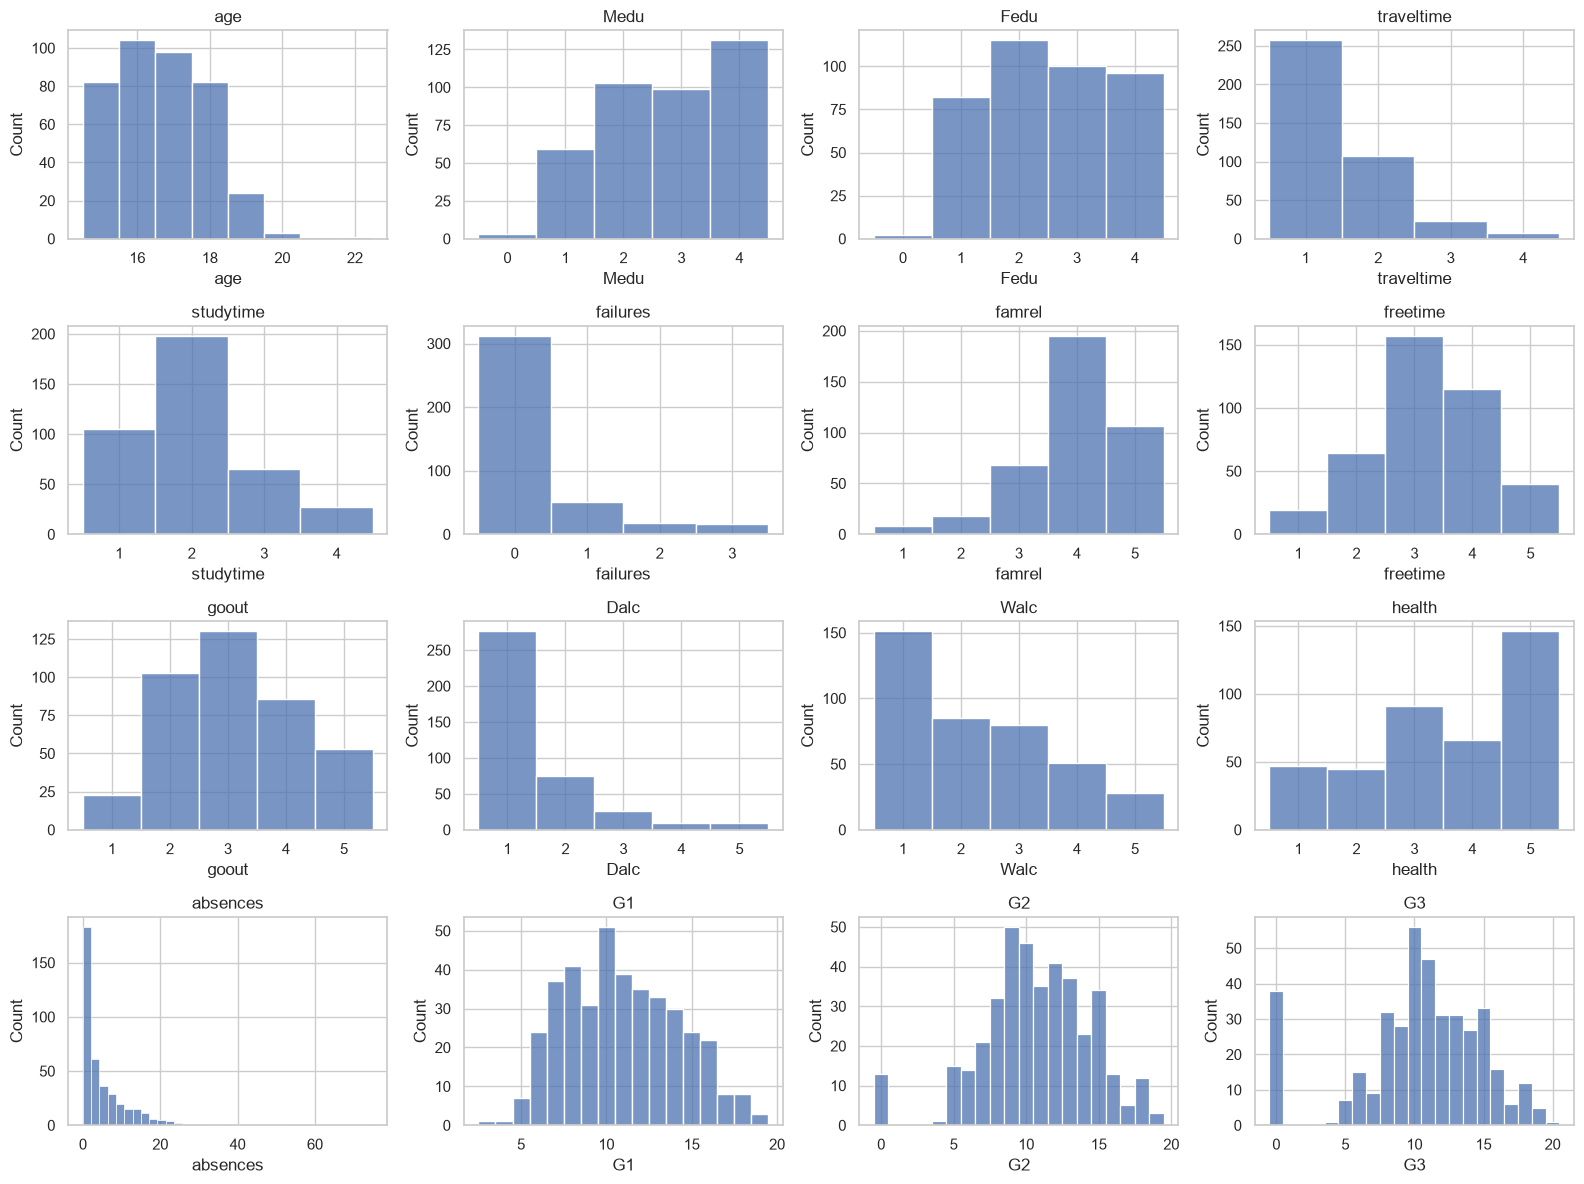

In [5]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.ravel(), numeric_cols + [TARGET_COLUMN]):
    sns.histplot(df[col], discrete=df[col].nunique() <= 25, ax=ax)
    ax.set_title(col)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "numeric_distributions.png", dpi=150)
plt.show()

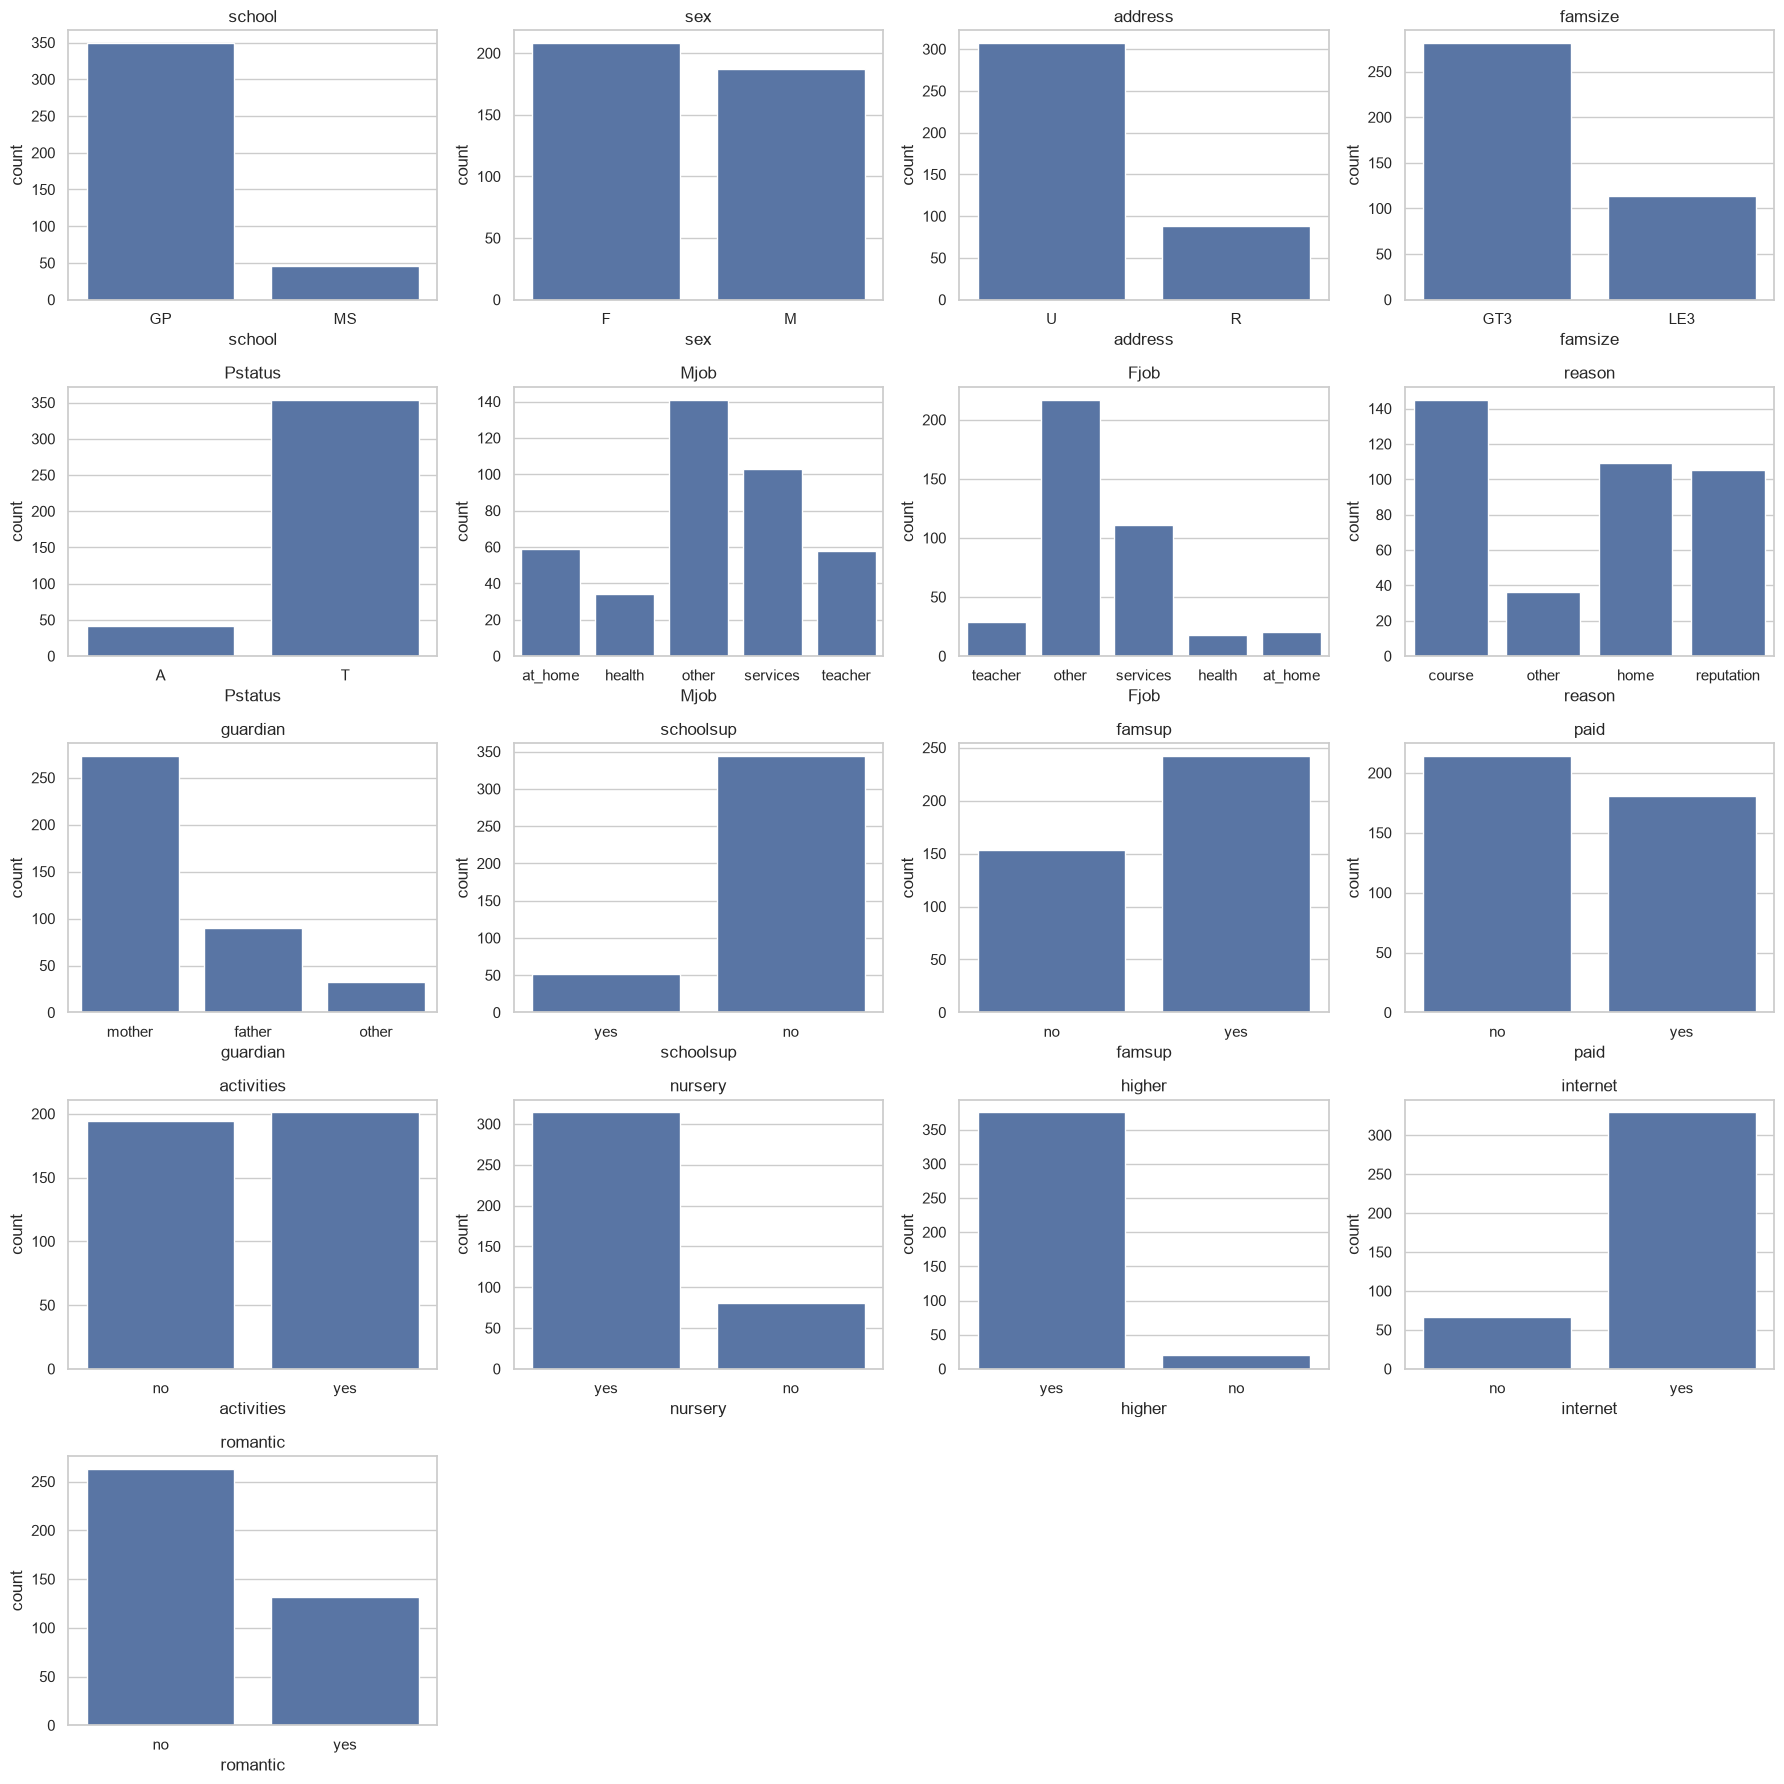

In [6]:
fig, axes = plt.subplots(5, 4, figsize=(18, 18))
axes = axes.ravel()
for ax, col in zip(axes, categorical_cols):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(col)
for ax in axes[len(categorical_cols):]:
    ax.set_visible(False)  # hide unused panels
plt.tight_layout()
fig.savefig(FIGURES_DIR / "categorical_distributions.png", dpi=150)
plt.show()

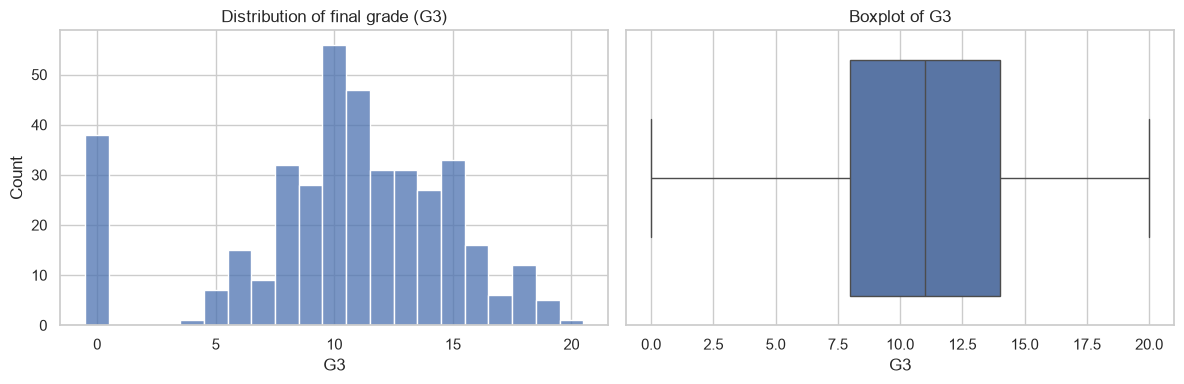

Students with G3 == 0: 38
count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET_COLUMN], discrete=True, ax=axes[0])
axes[0].set_title("Distribution of final grade (G3)")
sns.boxplot(x=df[TARGET_COLUMN], ax=axes[1])
axes[1].set_title("Boxplot of G3")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "target_distribution.png", dpi=150)
plt.show()

print("Students with G3 == 0:", int((df[TARGET_COLUMN] == 0).sum()))
print(df[TARGET_COLUMN].describe())

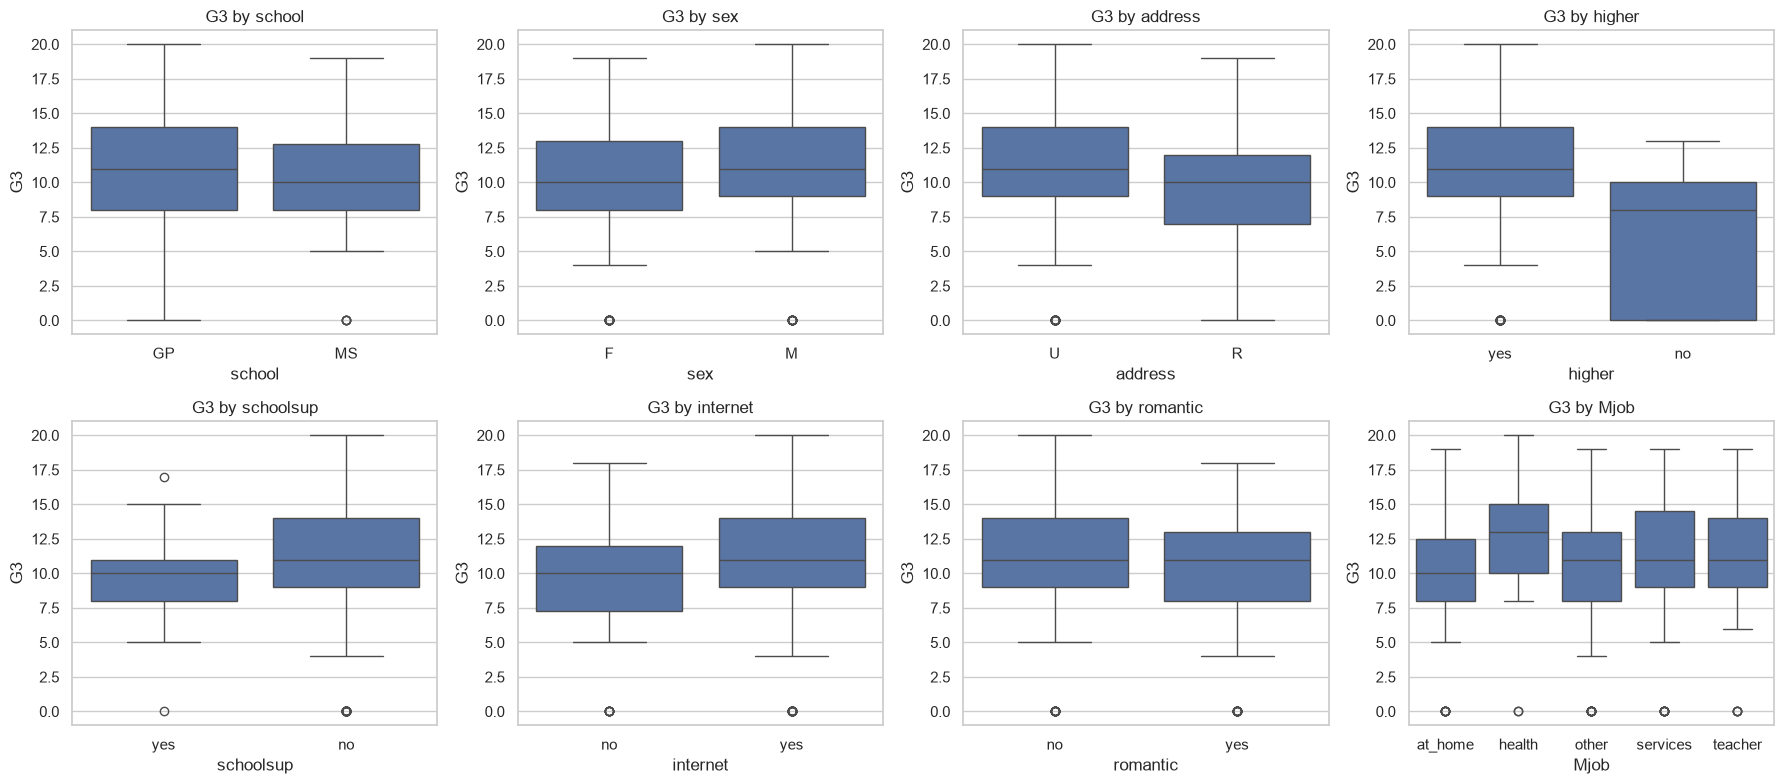

In [8]:
selected = ["school", "sex", "address", "higher", "schoolsup", "internet", "romantic", "Mjob"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), selected):
    sns.boxplot(data=df, x=col, y=TARGET_COLUMN, ax=ax)
    ax.set_title(f"G3 by {col}")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "target_by_categorical.png", dpi=150)
plt.show()

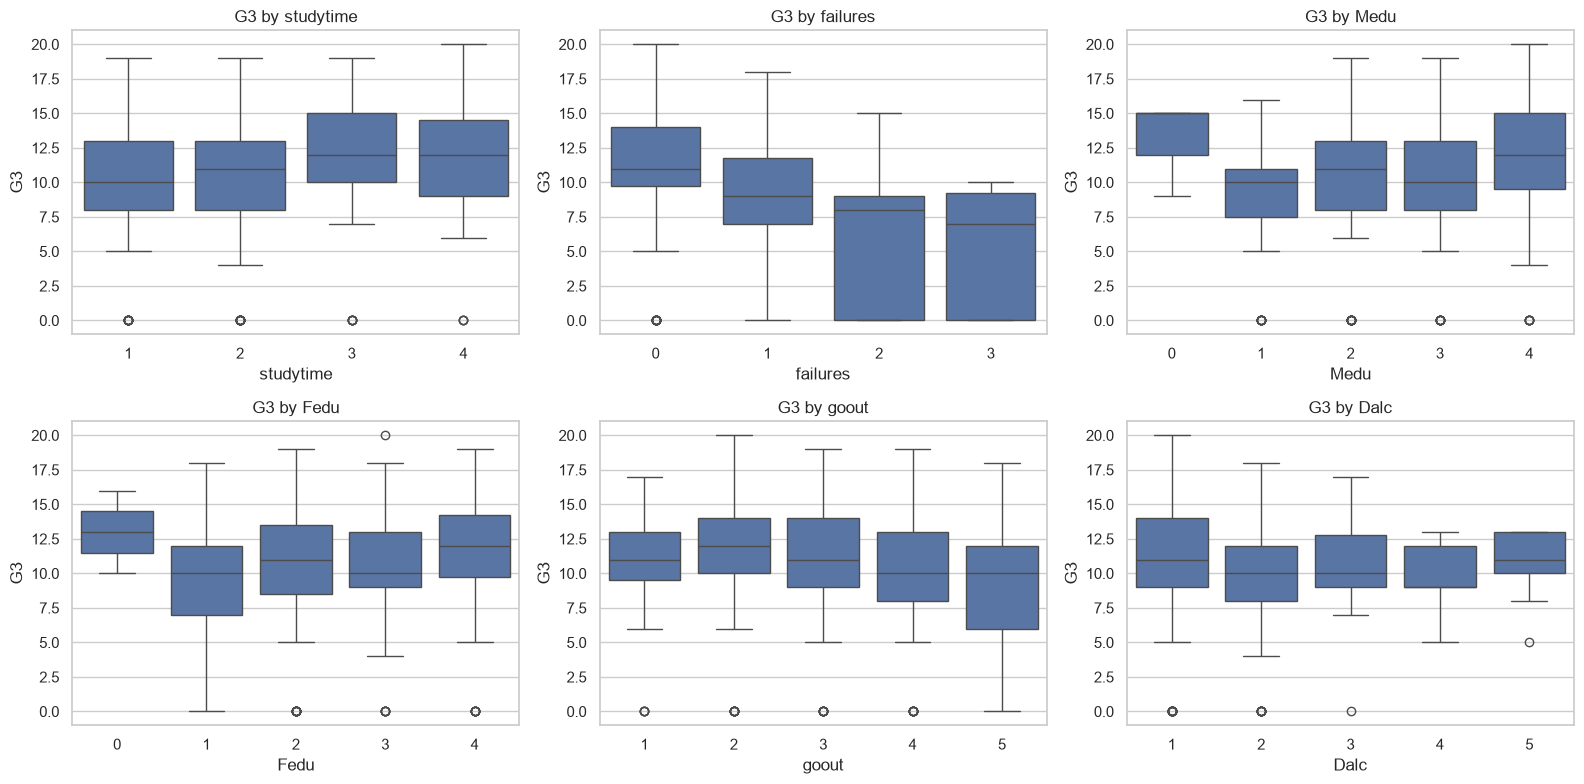


G3 by studytime:
           count   mean
studytime              
1            105  10.05
2            198  10.17
3             65  11.40
4             27  11.26

G3 by failures:
          count   mean
failures              
0           312  11.25
1            50   8.12
2            17   6.24
3            16   5.69


In [9]:
ordinal_cols = ["studytime", "failures", "Medu", "Fedu", "goout", "Dalc"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), ordinal_cols):
    sns.boxplot(data=df, x=col, y=TARGET_COLUMN, ax=ax)
    ax.set_title(f"G3 by {col}")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "target_by_ordinal.png", dpi=150)
plt.show()

# Group sizes matter: tiny groups give unreliable averages
for col in ["studytime", "failures"]:
    print(f"\nG3 by {col}:")
    print(df.groupby(col)[TARGET_COLUMN].agg(["count", "mean"]).round(2))

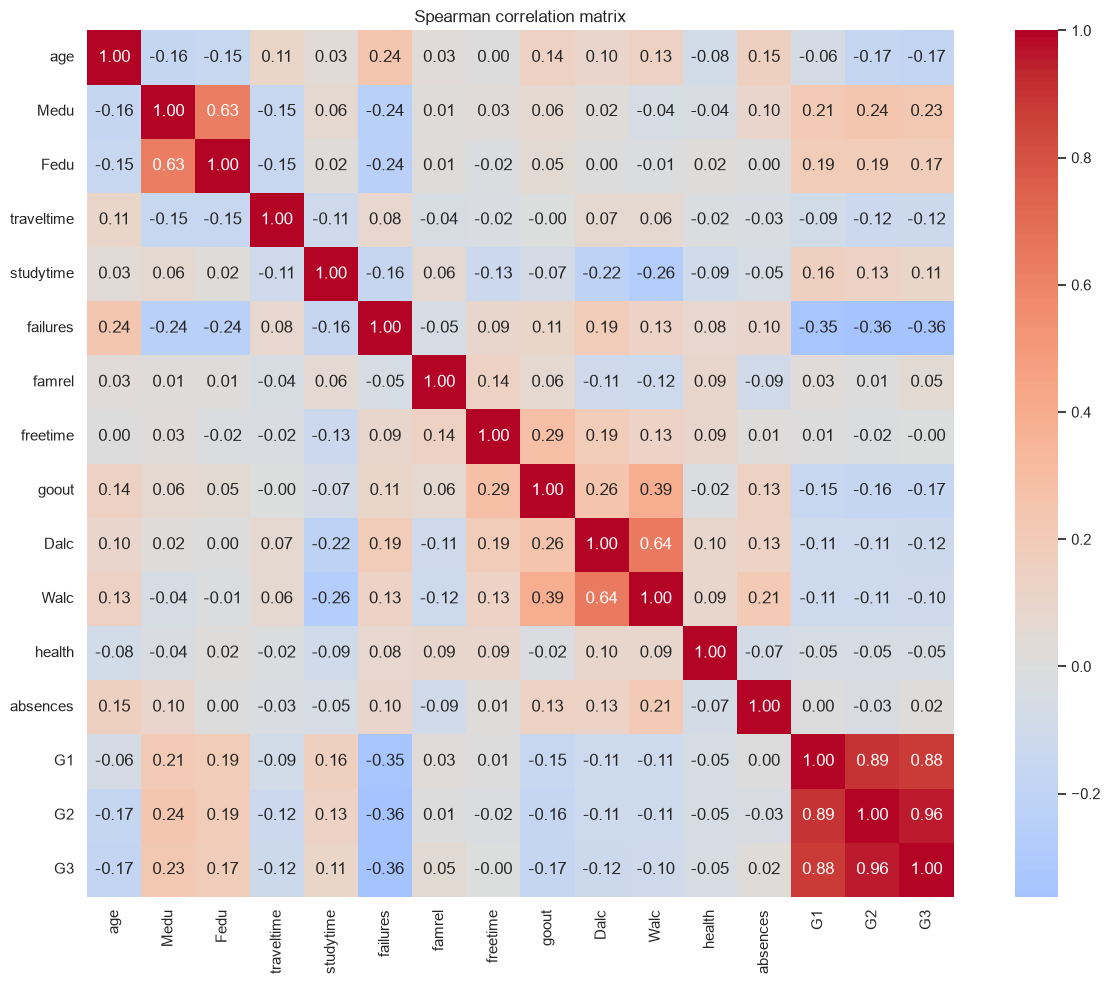

Spearman correlation with G3, strongest first:
G2            0.957
G1            0.878
failures     -0.361
Medu          0.225
age          -0.173
Fedu          0.170
goout        -0.166
Dalc         -0.121
traveltime   -0.121
studytime     0.105
Walc         -0.104
famrel        0.055
health       -0.048
absences      0.018
freetime     -0.005
Name: G3, dtype: float64


In [10]:
corr = df[numeric_cols + [TARGET_COLUMN]].corr(method="spearman")

plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Spearman correlation matrix")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "correlation_heatmap.png", dpi=150)
plt.show()

print("Spearman correlation with G3, strongest first:")
ranked = corr[TARGET_COLUMN].drop(TARGET_COLUMN)
print(ranked.reindex(ranked.abs().sort_values(ascending=False).index).round(3))

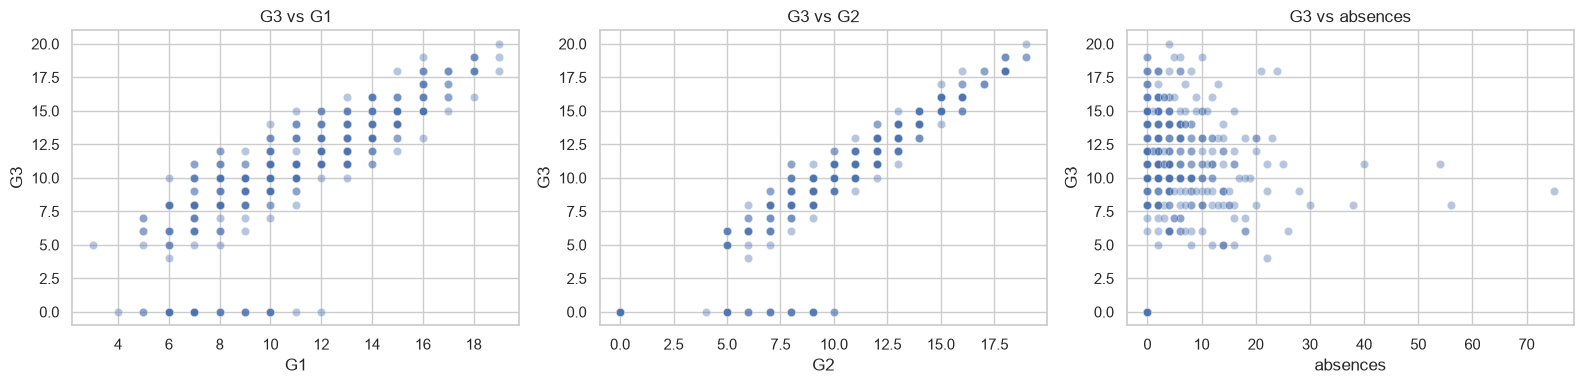

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["G1", "G2", "absences"]):
    sns.scatterplot(data=df, x=col, y=TARGET_COLUMN, alpha=0.4, ax=ax)
    ax.set_title(f"G3 vs {col}")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "scatter_key_features.png", dpi=150)
plt.show()

In [12]:
def iqr_outliers(series):
    """Return values outside 1.5 * IQR of the quartiles, plus the fences."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return series[(series < low) | (series > high)], low, high

for col in ["absences", "age", TARGET_COLUMN]:
    outliers, low, high = iqr_outliers(df[col])
    print(f"{col}: fences [{low:.1f}, {high:.1f}], {len(outliers)} flagged")
    if len(outliers) > 0:
        print("  flagged values:", sorted(outliers.unique()))

absences: fences [-12.0, 20.0], 15 flagged
  flagged values: [np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(28), np.int64(30), np.int64(38), np.int64(40), np.int64(54), np.int64(56), np.int64(75)]
age: fences [13.0, 21.0], 1 flagged
  flagged values: [np.int64(22)]
G3: fences [-1.0, 23.0], 0 flagged


In [16]:
zero_g3 = df[df[TARGET_COLUMN] == 0]
print("Students with G3 == 0:", len(zero_g3))
print("Of those, G2 == 0:", int((zero_g3["G2"] == 0).sum()))
print("Of those, G1 == 0:", int((zero_g3["G1"] == 0).sum()))

print("\nProfile of zero-G3 students:")
print(zero_g3[["G1", "G2", "absences", "failures"]].describe().round(2))

print("\nAbsences: G3 == 0 vs G3 > 0")
print(df.groupby(df[TARGET_COLUMN] == 0)["absences"].describe().round(2))

Students with G3 == 0: 38
Of those, G2 == 0: 13
Of those, G1 == 0: 0

Profile of zero-G3 students:
          G1     G2  absences  failures
count  38.00  38.00      38.0     38.00
mean    7.53   4.66       0.0      0.92
std     1.81   3.70       0.0      1.08
min     4.00   0.00       0.0      0.00
25%     6.00   0.00       0.0      0.00
50%     7.00   5.00       0.0      1.00
75%     9.00   8.00       0.0      1.75
max    12.00  10.00       0.0      3.00

Absences: G3 == 0 vs G3 > 0
       count  mean   std  min  25%  50%  75%   max
G3                                                
False  357.0  6.32  8.19  0.0  2.0  4.0  8.0  75.0
True    38.0  0.00  0.00  0.0  0.0  0.0  0.0   0.0


In [17]:
nonzero = df[df[TARGET_COLUMN] > 0]
print("Spearman absences vs G3, all students:      ",
      round(df["absences"].corr(df[TARGET_COLUMN], method="spearman"), 3))
print("Spearman absences vs G3, students with G3>0:",
      round(nonzero["absences"].corr(nonzero[TARGET_COLUMN], method="spearman"), 3))

zero_abs = df[df["absences"] == 0]
print("\nStudents with absences == 0:", len(zero_abs))
print("  of those with G3 == 0:", int((zero_abs[TARGET_COLUMN] == 0).sum()))
print("  share with G3 == 0:", round((zero_abs[TARGET_COLUMN] == 0).mean(), 3))

Spearman absences vs G3, all students:       0.018
Spearman absences vs G3, students with G3>0: -0.244

Students with absences == 0: 115
  of those with G3 == 0: 38
  share with G3 == 0: 0.33


## Summary of observations

- **Data quality:** 395 rows, 33 columns. No missing values, no duplicate rows, no values outside documented ranges, no inconsistent category labels.
- **Target (G3):** range 0-20, median 11, mean 10.4. 38 students (about 9.6%) have G3 = 0, forming a separate cluster at the low end.
- **Strongest relationships with G3 (Spearman):** G2 (0.957), G1 (0.878), failures (-0.361), Medu (0.225). All other features are below 0.18 in absolute value.
- **Leakage concern:** G1 and G2 almost determine G3. Models will be built and compared with and without them.
- **Zero grades:** all 38 have absences = 0; 13 have G2 = 0, none has G1 = 0. Of the 115 students with absences = 0, 33% have G3 = 0; no student with absences > 0 does. Reason unknown, possibly a recording artifact.
- **Absences:** Spearman with G3 is 0.018 for all students but -0.244 among students with G3 > 0, so the zero-grade group masks the relationship.
- **Outliers:** absences up to 75 (15 students above the IQR fence of 20); one student aged 22. Plausible values, not removed.
- **Group observations:** mean G3 falls steadily with past failures: 11.25 (0), 8.12 (1), 6.24 (2), 5.69 (3). The groups for 2 and 3 failures are small (17 and 16 students). Study time shows only a weak pattern: means of 10.05, 10.17, 11.40, 11.26 for levels 1 to 4 (group sizes 105, 198, 65, 27). These means include the zero-grade students, who are concentrated among students with failures.
- **Scatter plots:** G3 rises roughly linearly with G1 and, more tightly, with G2. The 38 zero-grade students form a separate row along G3 = 0 that earlier grades do not explain (G1 from 4 to 12, G2 from 0 to 10). G3 vs absences shows no clear trend, and all G3 = 0 points sit at absences = 0.
- **Implication:** a model using G2 will mispredict the zero-grade students by a large margin, so overall error will be dominated by them. Errors should be reported separately for G3 = 0 and G3 > 0.
- **Open questions for preprocessing:** treatment of zero grades, skewed absences, ordinal-coded columns, whether to include G1/G2 (addressed in Phase 4: zeros kept, outliers kept, ordinals treated as ordered numbers, G1/G2 as a switch).
- **Caution:** correlations and group differences here show association, not cause.

SyntaxError: invalid syntax (2819418005.py, line 1)